# 🤖 Agente inteligente mediante aprendizaje por refuerzo
**Q-learning en un laberinto 8×8** · Notebook de portafolio

**Objetivo:** desarrollar y evaluar un agente que aprende una política a partir de recompensas, sin que le indiquemos manualmente la ruta.

## 1. Preparación
Ejecuta este cuaderno desde la raíz del proyecto en VS Code o Jupyter. Si hace falta, instala las dependencias con `pip install -r requirements.txt`.

In [6]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from src.gridworld import GridWorld
from src.qlearning import train, evaluate, policy_text
print('Proyecto:', root)

Proyecto: c:\Proyectos\02_Agente_Inteligente_Qlearning


## 2. Conocer el entorno
El agente parte de **S**, busca **G**, evita **█** (muros) y **X** (trampas). Cada paso tiene un costo para favorecer rutas cortas.

In [7]:
env = GridWorld()
print(env.render_ascii())
print('Estados:', env.size ** 2, 'Acciones:', 4)

S              
  █ █ █        
      █   X    
      █     X  
  █ █          
          █    
      X   █    
              G
Estados: 64 Acciones: 4


## 3. Fundamentos del algoritmo
La regla de actualización es:

$$Q(s,a) \leftarrow Q(s,a)+\alpha [r+\gamma \max_{a'} Q(s',a')-Q(s,a)]$$

- $\alpha$: tasa de aprendizaje.
- $\gamma$: importancia de recompensas futuras.
- $\epsilon$: probabilidad de explorar una acción al azar (epsilon-greedy).

Con cada episodio, el agente actualiza la tabla de valores Q.

In [8]:
resultado = train(episodes=4000, seed=42, alpha=0.18, gamma=0.97)
print('Tabla Q:', resultado.q_table.shape)
print('Éxitos en los últimos 100 episodios:', f'{np.mean(resultado.success[-100:]):.1%}')

Tabla Q: (64, 4)
Éxitos en los últimos 100 episodios: 99.0%


## 4. Aprendizaje observado
Se representa una media móvil para evitar que el ruido de episodios individuales oculte la tendencia.

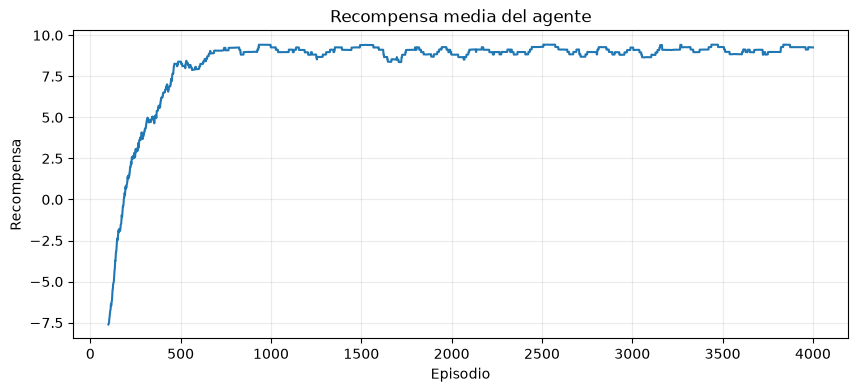

In [9]:
window = 100
media = np.convolve(resultado.returns, np.ones(window)/window, mode='valid')
plt.figure(figsize=(10, 4))
plt.plot(np.arange(window, len(resultado.returns)+1), media)
plt.title('Recompensa media del agente'); plt.xlabel('Episodio'); plt.ylabel('Recompensa'); plt.grid(alpha=.25); plt.show()

## 5. Política y evaluación greedy
Se evalúa el agente sin exploración, empezando siempre desde la casilla inicial. La tasa de éxito no mide generalización a mapas nuevos.

In [10]:
metricas = evaluate(resultado.q_table, episodes=50)
print(policy_text(resultado.q_table))
print('Éxito:', f"{metricas['success_rate']:.1%}")
print('Pasos promedio:', metricas['avg_steps'])
print('Recorrido:\n', env.render_ascii(metricas['example_path']))

S → → → ↓ ← ↓ ↓
↑ ■ ■ ■ ↓ ← → ↓
↓ → ↓ ■ ↓ X → ↓
↓ ← ↑ ■ ↓ ↓ X ↓
↓ ■ ■ ↓ ↓ → ↓ ↓
↓ → → → ↓ ■ → ↓
→ → ↓ X ↓ ■ ↓ ↓
→ → → → → → → G
Éxito: 100.0%
Pasos promedio: 14.0
Recorrido:
 S · · · ·      
  █ █ █ ·      
      █ · X    
      █ ·   X  
  █ █   ·      
        · █    
      X · █    
        · · · G


## 6. Conclusiones y mejoras
- Q-learning puede encontrar una política útil a partir de recompensas cuando el espacio de estados es reducido.
- Los hiperparámetros (α, γ y ε) afectan el aprendizaje.
- La tabla tabular escala mal para estados muy numerosos.

**Próximos pasos:** añadir mapas aleatorios, comparar con SARSA y medir el desempeño en nuevas distribuciones de entornos.